In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
from IPython.display import display
warnings.simplefilter("ignore")
%matplotlib inline

In [2]:
data = pd.read_csv("Titanic-Dataset.csv")

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

data_new = data.copy()
data_new["Family"] = data_new["SibSp"] + data_new["Parch"]
data_new["Title"] = data_new["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
data_new["Title"] = data_new["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
data_new["Title"] = data_new["Title"].where(data_new["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
data_new = data_new.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "SibSp", "Parch"])

y = data_new["Survived"]
X = data_new.drop(columns=["Survived"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# stratify=y - доля выживших одинакова в train и test
# random_state=42 - разбиение всегда одинаковое
print("Размер train:", X_train.shape, "Размер test:", X_test.shape)

Размер train: (712, 7) Размер test: (179, 7)


In [4]:
num = ["Age", "Fare", "Family"]            # числовые
cat = ["Pclass", "Sex", "Embarked", "Title"]        # категориальные

# для деревьев: без масштабирования
preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num), # медиана для чисел
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # часто встречаемое для категорий
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat),
])

In [5]:
from sklearn.ensemble import RandomForestClassifier

baseline = Pipeline([
    ("prep", preprocess_tree),
    ("model", RandomForestClassifier(random_state=42, n_jobs=-1)),
])

Random Forest - ансамблевый алгоритм, строит множество независимых деревьев решений и объединяет их прогнозы (голосование большинства).

Каждое дерево обучается на случайной подвыборке объектов.

В узле рассматривается случайное подмножество признаков.

In [6]:
from sklearn.metrics import f1_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

crossV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_Score = cross_val_score(baseline, X_train, y_train, cv=crossV, scoring="f1")

print("Исходные параметры Baseline:")
for param, value in baseline.named_steps['model'].get_params().items():
    print(f"  {param}: {value}")

print("\n")  
print("F1 по отдельным фолдам:", np.round(baseline_Score, 3))
print("\n")
print(f"Среднее качество Baseline:, {baseline_Score.mean():.3f}")

Исходные параметры Baseline:
  bootstrap: True
  ccp_alpha: 0.0
  class_weight: None
  criterion: gini
  max_depth: None
  max_features: sqrt
  max_leaf_nodes: None
  max_samples: None
  min_impurity_decrease: 0.0
  min_samples_leaf: 1
  min_samples_split: 2
  min_weight_fraction_leaf: 0.0
  monotonic_cst: None
  n_estimators: 100
  n_jobs: -1
  oob_score: False
  random_state: 42
  verbose: 0
  warm_start: False


F1 по отдельным фолдам: [0.771 0.727 0.752 0.727 0.745]


Среднее качество Baseline:, 0.745


Кросс-валидация - метод, при котором train делится на k равных частей (folds). Модель обучается по очереди на k-1 частях, на оставшейся части тестируется. Результаты усредняются.

Для выбора подбора гиперпараметров используется только train. Если многократно выбирать гиперпараметры на test произойдет утечка информации и переобучение.

Зачем нужна кросс-валидация? - Чтобы оценивать качество и подбирать гиперпараметры, не трогая test. Каждый объект train по очереди попадает в валидацию, поэтому оценка использует все данные, усредняется по k разбиениям. Получается более объективная оценка качества модели.

Одного разбиения train/test недостаточно, так как результат зависит от того, какие именно объекты попали в валидацию, модель может переобучится на одном разбиении.

k = 5 - стандартное значение, обучающая часть составляет 80%, а тестовая 20%.

Выбрали 3 значимых гиперпараметра:

 n_estimators (количество деревьев в лесу): 

  Задает общее количество деревьев решений в ансамбле; 

  Разумный диапазон от 50 до 300;

  Влияние: с увеличением количества деревьев предсказание модели становится стабильнее, точность растет, но после определенного числа рост качества останавливается, а время обучения растет линейно. 

 max_depth (максимальная глубина дерева):

  Задает высоту дерева; 

  Разумный диапазон от 3 до 16;

  Влияние: слишком маленьгая глубина приведет к недообучению, а слишком большая к переобучению.

 min_samples_leaf (минимальное число объектов в листе):

  Задает min количество элементов в листе дерева; 

  Разумный диапазон от 1 до 10;
  
  Влияние: если увеличить значение до 10 , например, то дерево будет принимать решения на основе более крупных групп объектов, что сделает модель более устойчивой и защищенной от переобучения.

In [7]:
from sklearn.model_selection import GridSearchCV
import time

grid = {
        "model__n_estimators": [50, 100, 150, 200, 300],
        "model__max_depth": [3, 6, 9, 12, 16],
        "model__min_samples_leaf": [1, 3, 5, 7, 10]
}

combinations = (
    len(grid["model__n_estimators"]) * 
    len(grid["model__max_depth"]) * 
    len(grid["model__min_samples_leaf"])
)
print(f"Всего комбинаций в сетке Grid Search: {combinations}")

grid_search = GridSearchCV(
    estimator=baseline,
    param_grid=grid,
    scoring="f1",
    cv=crossV,
    n_jobs=-1                   # для ускорения
)

start_time = time.time()
grid_search.fit(X_train, y_train)
grid_time = time.time() - start_time

print(f"\nGrid Search: Время выполнения поиска - {grid_time:.2f} секунд.")
print(f"Лучший набор гиперпараметров: {grid_search.best_params_}")
print(f"Лучшее качество (F1 на кросс-валидации): {grid_search.best_score_:.3f}")

Всего комбинаций в сетке Grid Search: 125

Grid Search: Время выполнения поиска - 52.74 секунд.
Лучший набор гиперпараметров: {'model__max_depth': 9, 'model__min_samples_leaf': 1, 'model__n_estimators': 50}
Лучшее качество (F1 на кросс-валидации): 0.768


In [8]:
from sklearn.model_selection import RandomizedSearchCV

param_distributions = {
    "model__n_estimators": [50, 100, 150, 200, 300],
    "model__max_depth": [3, 6, 9, 12, 16],
    "model__min_samples_leaf": [1, 3, 5, 7, 10]
}

random_search = RandomizedSearchCV(
    estimator=baseline,
    param_distributions=param_distributions,
    n_iter=20,              # 20 случайных комбинаций из всего пр-ва - вычислительный бюджет
    scoring="f1",
    cv=crossV,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()
random_search.fit(X_train, y_train)
random_time = time.time() - start_time

print(f"Random Search: Время выполнения поиска - {random_time:.2f} секунд.")
print(f"Лучший набор гиперпараметров: {random_search.best_params_}")
print(f"Лучшее качество (F1 на кросс-валидации): {random_search.best_score_:.3f}")

Random Search: Время выполнения поиска - 8.49 секунд.
Лучший набор гиперпараметров: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 3}
Лучшее качество (F1 на кросс-валидации): 0.765


ВЫВОДЫ для Grid Search (полный перебор):

 Пространство поиска: для каждого параметра по 5 вариантов;

 Всего комбинаций в сетке: 125. Учитывая кросс-валидацию на 5 частях, суммарно 625;

 Лучший набор гиперпараметров: {'model__max_depth': 9, 'model__min_samples_leaf': 1, 'model__n_estimators': 50};

 Лучшее качество (F1 на кросс-валидации): 0.768;

 Время выполнения поиска - 49.70 секунд.


ВЫВОДЫ для RandomizedSearch (Случайный поиск):

 Проверено 20 комбинаций;

 Лучший набор гиперпараметров: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_depth': 3};

 Лучшее качество (F1 на кросс-валидации): 0.765;

 Время выполнения поиска - 7.09 секунд.


Сравнение:

-Оба метода показали почти одинаковое качество, разница = 0,003, это говорит о высокой стаильности ансамбля деревьев.

-Grid Search проверил 125 комбинаций, а RandomizedSearch всего 20 (сопоставимый вычислительный бюджет). 

-RandomizedSearch нашел почти тот же результат, проверя около 15% от общего числа вариантов, по времени почти в 7 раз быстрее Grid Search. 

-То есть RandomizedSearch при значительно меньших затратах ресурсов позволяет найти решение, почти не уступающее Grid Search.

-RandomizedSearch предпочтительнее Grid Search в случаях, когда у нас огромное пространство поиска, ограниченное время.

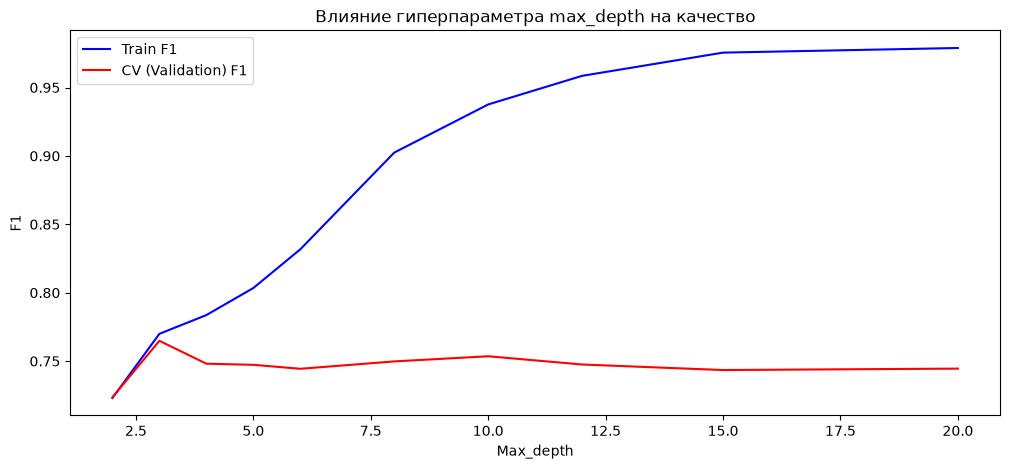

In [9]:
from sklearn.model_selection import cross_validate

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
train_scores_dp = []
cv_scores_dp = []

for d in depths:
    pipeline = Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestClassifier(max_depth=d, random_state=42, n_jobs=-1))
    ])
    
    # считаем как на обучающих фолдах (return_train_score=True), 
    # так и на валидационных (те же самые части как и при обучении)
    scores = cross_validate(pipeline, X_train, y_train, cv=crossV, scoring="f1", return_train_score=True)
    
    train_scores_dp.append(scores['train_score'].mean())
    cv_scores_dp.append(scores['test_score'].mean())

plt.figure(figsize=(12, 5))
plt.plot(depths, train_scores_dp, label='Train F1', color='blue')
plt.plot(depths, cv_scores_dp, label='CV (Validation) F1', color='red')
plt.xlabel('Max_depth')
plt.ylabel('F1')
plt.title('Влияние гиперпараметра max_depth на качество')
plt.legend()
plt.show()

Выводы по графику Влияние гиперпараметра max_depth на качество:

Область недообучения max_depth = 2 - обе кривые низкие и почти совпадают. Деревья слишком простые - не успевают выучить закономерности.

Разумная сложность от 3 до 5 - кривая кросс-валидации(CV) пик при max_depth = 3 (0.765), при этом train (0.770) почти равен CV - разрыв маленький. Дальше CV держится на уровне около 0.745 - 0.754, то есть усложнение дерева на новых данных не добавляет качества. Модель достаточно сложная, чтобы отслеживать закономерности, влияющие на выживаемость пассажиров.

Область переобучения от 6 - кривая train продолжает расти (устремляется к 1), а CV не растет и остается около 0.745. Разрыв между train и CV увеличивается. Модель подстраивается под шум конкретных объектов, а не находит новые закономерности.

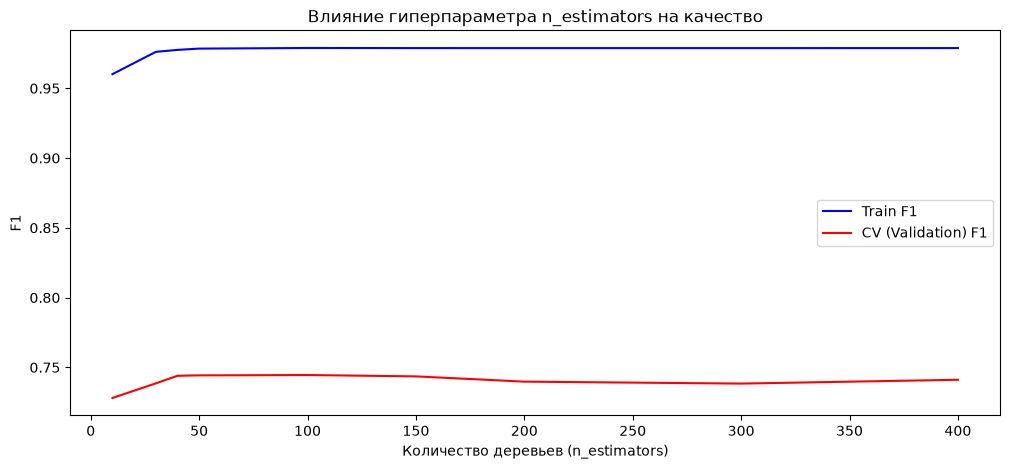

In [10]:
n_estimators = [10, 30, 40, 50, 100, 150, 200, 300, 400]
train_scores_ne = []
cv_scores_ne = []

for n in n_estimators:
    pipeline1 = Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1))
    ])
    scores = cross_validate(pipeline1, X_train, y_train, cv=crossV, scoring="f1", return_train_score=True)
    train_scores_ne.append(scores['train_score'].mean())
    cv_scores_ne.append(scores['test_score'].mean())

plt.figure(figsize=(12, 5))
plt.plot(n_estimators, train_scores_ne, label='Train F1', color='blue')
plt.plot(n_estimators, cv_scores_ne, label='CV (Validation) F1', color='red')
plt.xlabel('Количество деревьев (n_estimators)')
plt.ylabel('F1')
plt.title('Влияние гиперпараметра n_estimators на качество')
plt.legend()
plt.show()

Выводы по графику Влияние гиперпараметра n_estimators на качество:

Область "недообучения" от 10 до 30 - CV самое низкое и разброс между fold больше (std 0.027 при 10, около 0.015 при 50 и выше). Это не недообучение в обычном смысле (train уже 0.96): маленький лес нестабилен, потому что усреднение по малому числу случайных деревьев не успевает «сгладить» ошибки отдельных деревьев.

Разумная сложность (40 - 150): CV выходит на уровень около 0.744 - 0.745, дальше качество не растет.

Много деревьев (200-300) - CV не растет и колеблется в пределах 0.738 - 0.741 (это шум), train не меняется. Переобучения от увеличения числа деревьев нет: деревья независимы, усреднение уменьшает дисперсию, а смещение (bias) не меняется. Рост n_estimators только увеличивает время обучения линейно..

Больше деревьев (200 - 400): CV не растет и колеблется в пределах 0.738 - 0.741 (это шум), train неизменен (0.979). Переобучения от увеличения числа деревьев нет: деревья независимы, усреднение уменьшает дисперсию, а смещение (bias) не меняется. Рост n_estimators только увеличивает время обучения линейно.

Вывод: n_estimators нужно взять достаточно большим для стабильности (порядка 50 - 150), дальше смысла нет. Поэтому в отличие от max_depth и min_samples_leaf здесь «области переобучения» нет, есть область нестабильности (мало деревьев) и область разумной сложности.

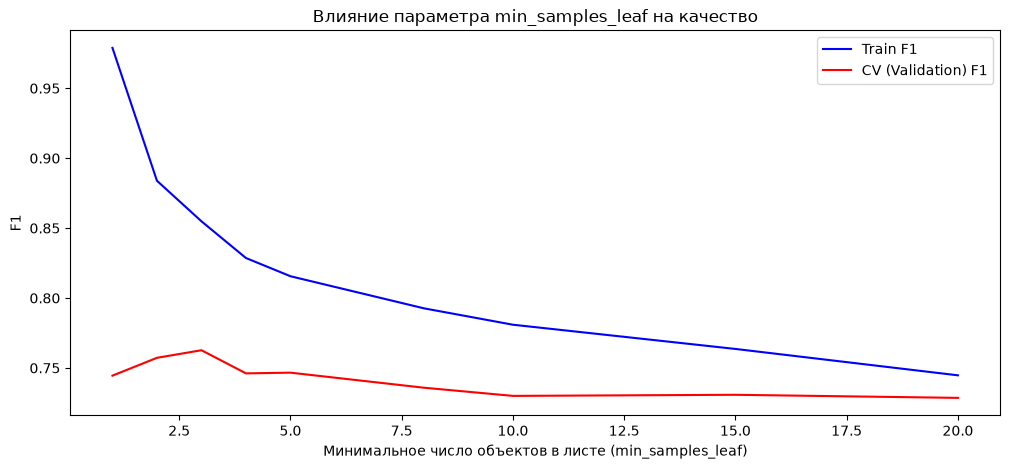

In [11]:
min_samples_leaf = [1, 2, 3, 4, 5, 8, 10, 15, 20]
train_scores_msl = []
cv_scores_msl = []

for m in min_samples_leaf:
    pipeline2 = Pipeline([
        ("prep", preprocess_tree),
        ("model", RandomForestClassifier(min_samples_leaf=m, random_state=42, n_jobs=-1))
    ])
    scores = cross_validate(pipeline2, X_train, y_train, cv=crossV, scoring="f1", return_train_score=True)
    train_scores_msl.append(scores['train_score'].mean())
    cv_scores_msl.append(scores['test_score'].mean())

plt.figure(figsize=(12, 5))
plt.plot(min_samples_leaf, train_scores_msl, label='Train F1', color='blue')
plt.plot(min_samples_leaf, cv_scores_msl, label='CV (Validation) F1', color='red')
plt.xlabel('Минимальное число объектов в листе (min_samples_leaf)')
plt.ylabel('F1')
plt.title('Влияние параметра min_samples_leaf на качество')
plt.legend()
plt.show()

Выводы по графику Влияние гиперпараметра min_samples_leaf на качество:

Область переобучение (min_samples_leaf = 1): train 0.979, CV 0.745 - самый большой разрыв (0.23) - листья из 1 объекта запоминают обучающую выборку.

Разумная сложность от 2 до 5 - CV лучше всего, train при этом падает до 0.82 - 0.88, разрыв сокращается. Небольшая регуляризация помогает.

Область недообучение от 8 -  CV падает до 0.73, train падает до 0.745, а разрыв почти исчезает (0.016 при 20). Требование 15-20 объектов в листе делает деревья слишком грубыми (принимает решения на основе более крупных групп объектов), и модель теряет полезные закономерности.

Оптимально - небольшие значения (примерно 2 - 5). НО гиперпараметры влияют друг на друга. Поэтому кривые по одному параметру (остальные по умолчанию) не объективны, только дают ориентир.

In [12]:
# финальная модель
baseline.fit(X_train, y_train)

models = {
    "Baseline": baseline,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
}
cv_f1 = {
    "Baseline": baseline_Score.mean(),
    "Grid Search": grid_search.best_score_,
    "Random Search": random_search.best_score_,
}

rows = []
for name, model in models.items():
    rows.append({
        "модель": name,
        "CV F1": cv_f1[name],
        "Test F1": f1_score(y_test, model.predict(X_test)),
    })

final = pd.DataFrame(rows).set_index("модель")
final["Δ CV"] = final["CV F1"] - final.loc["Baseline", "CV F1"]
final["Δ Test"] = final["Test F1"] - final.loc["Baseline", "Test F1"]
display(final.round(3))

,CV F1,Test F1,Δ CV,Δ Test
модель,,,,
Baseline,0.745,0.752,0.000,0.000
Grid Search,0.768,0.769,0.023,0.017
Random Search,0.765,0.724,0.020,-0.027


ВЫВОДЫ:

Δ CV - насколько CV F1 выше, чем у baseline.
Δ Test - насколько Test F1 выше, чем у baseline.

Baseline - это лес с настройками по умолчанию, точка отсчёта.
Grid Search - это лес с настройками, найденными полным перебором 125 комбинаций.
Random Search - это лес с настройками, найденными среди 20 случайных комбинаций.

Насколько оптимизация улучшила качество:

на кросс-валидации примерно на 0.02 (Grid +0.023, Random +0.020). 

На test Grid Search лучше baseline на 0.017, а Random Search хуже на 0.027. 

Улучшение небольшое, меньше разброса между fold (около 0.04), поэтому существенным его считать нельзя. Случайный лес с параметрами по умолчанию уже хорошо работает на этих данных: сигнал простой (в основном Sex, Title, Pclass).

Совпадает ли улучшение на кросс-валидации с результатом на test:

у Grid Search ДА (+0.023 на CV и +0.017 на test). 

У Random Search нет: на CV он лучше baseline, а на test хуже.

Чем это объясняется:
1. Test маленький (179 объектов, 69 выживших) - разница в 0.027 - это несколько объектов.
2. Лучший набор выбирался по шумной оценке из многих комбинаций, поэтому оценка на CV немного оптимистична. Комбинации с почти одинаковым CV по сути неразличимы.
3. Random Search выбрал очень простую модель (max_depth=3), Grid Search - более глубокую (max_depth=9). По CV они одинаково хороши, а на конкретном test порядок мог поменяться.

Итог: 

финальной моделью выбираем Grid Search, так как у неё лучший CV F1. Все различия между моделями небольшие и лежат в пределах шума.

,Baseline,Grid Search,Random Search
fold 1,0.771,0.800,0.782
fold 2,0.727,0.716,0.725
fold 3,0.752,0.820,0.846
fold 4,0.727,0.762,0.712
fold 5,0.745,0.742,0.760


,Baseline,Grid Search,Random Search
mean,0.745,0.768,0.765
std,0.018,0.042,0.053
min,0.727,0.716,0.712
max,0.771,0.820,0.846


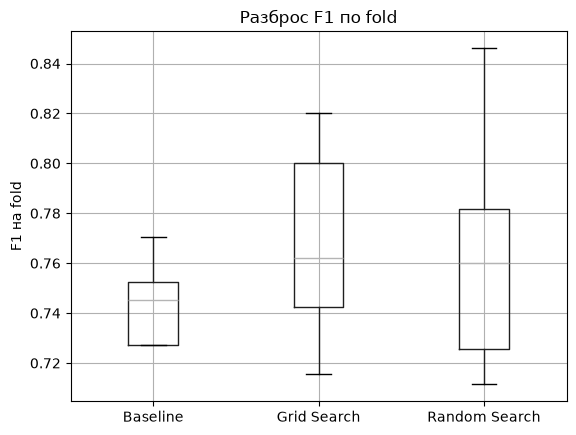

In [14]:
# анализ устойчивости
from sklearn.base import clone

grid_model = clone(baseline).set_params(**grid_search.best_params_)
rand_model = clone(baseline).set_params(**random_search.best_params_)

# F1 на каждом из 5 fold
folds = pd.DataFrame({
    "Baseline": baseline_Score,
    "Grid Search": cross_val_score(grid_model, X_train, y_train, cv=crossV, scoring="f1"),
    "Random Search": cross_val_score(rand_model, X_train, y_train, cv=crossV, scoring="f1"),
})
folds.index = [f"fold {i}" for i in range(1, 6)]

display(folds.round(3))
display(folds.agg(["mean", "std", "min", "max"]).round(3))

folds.boxplot()
plt.ylabel("F1 на fold")
plt.title("Разброс F1 по fold")
plt.show()

ВЫВОДЫ по устойчивости:

mean среднее. Это и есть «CV F1»: 0.745, 0.768, 0.765.

std стандартное отклонение, то есть насколько результаты в среднем отличаются от среднего. Чем оно больше, тем сильнее результат зависит от того, какие люди попали в fold.

min и max худший и лучший fold.

Средние F1 на кросс-валидации почти одинаковые (Grid Search 0.768, Random Search 0.765), но по отдельным fold они различаются:

 Baseline:      от 0.727 до 0.771, std = 0.018
 Grid Search:   от 0.716 до 0.820, std = 0.042
 Random Search: от 0.712 до 0.846, std = 0.053

Оптимизированные модели в среднем лучше baseline, но менее стабильны: их результат сильнее колеблется от fold к fold. Улучшение (около 0.02) меньше разброса (std 0.04 - 0.05), то есть может быть частично случайным.

Почему две модели с одинаковым средним могут различаться по устойчивости:
 1. Среднее скрывает разброс: одно и то же среднее получается при разных результатах (могут быть одинаковые или чередование удачных и неудачных fold).
 2. Модели по-разному реагируют на то, какие объекты попали в обучение и валидацию.
 3. Fold маленькие (около 143 объектов), поэтому F1 на одном fold сам по себе шумит.

Вывод: 

При выборе модели смотрим не только среднее F1 на кросс-валидации, но и результаты по каждому fold. У подобранных моделей среднее выше, но разброс больше, а улучшение (0.02) меньше разброса (0.04–0.05), поэтому я считаю его небольшим и не вполне надёжным. При близких средних лучше выбирать более устойчивую модель.